<a href="https://colab.research.google.com/github/mintus2511/ADL_230167_Assignment2/blob/main/Assignment_BERT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment: Sentiment classification with BERT - Exploiting multi-layer feature extraction

`imdb_reviews` dataset is a large movie review dataset. This dataset is for binary sentiment classification containing a set of 25,000 highly polar movie reviews for training, and 25,000 for testing. All the reviews have either a *positive* or *negative* sentiment.
Reference: http://ai.stanford.edu/~amaas/data/sentiment/

Each data sample contains:
* label (tf.int64)
* text (tf.string)

In this assignment, you will exploit multi-layer feature extraction of a BERT model which comprises of several Transformer-encoder blocks. The model you will be using is as follows:
- Name: small_bert/bert_en_uncased_L-4_H-128_A-2
- Number of layers, i.e., Transformer-encoder blocks: 4.
- Number of hidden states: 128.
- Number of attention heads: 2.
- Model on TFHub: https://tfhub.dev/tensorflow/small_bert/bert_en_uncased_L-4_H-128_A-2/1
- Preprocessing module on TFHub: https://tfhub.dev/tensorflow/bert_en_uncased_preprocess/3

Since the BERT model has 4 encoder blocks and each outputs an embedding feature vector, your task is to find a way to make use of the multi-layer features to boost the classification accuracy. There are some questions you need to figure out:
- How to get embedding feature vector of each encoder block.
- How to combine the embedding feature vectors of the encoder blocks.
- How to make use of the combined embedding feature vector to boost the model performance.

1.  **(5 points) Coding Tasks:** The following questions involve writing code to complete specific tasks.  
    1.1 *(1 point)* Tokenize and preprocess the IMDB dataset using the BERT preprocessing module from TFHub. Show the code that prepares the text data for the BERT model.  
    1.2 *(1 point)* Extract the embedding feature vectors from each of the four encoder blocks in the BERT model. Provide the code to retrieve these embeddings.  
    1.3 *(1 point)* Combine the embedding feature vectors from the four encoder blocks into a single vector. Show the code used for concatenating or pooling the embeddings.  
    1.4 *(1 point)* Construct the classification model using the combined embedding feature vector. Provide the code for building the model.   
    1.5 *(1 point)* Evaluate the performance of your model on the test set. Provide the code to compute accuracy or other relevant metrics.  

2.  **(5 points) Open discussion questions:** These discussion questions ask you to analyze and argue your points.  Feel free to include relevant code examples to strengthen your arguments.  
    2.1 *(1 point)* What effect do you think the preprocessing step (tokenization, padding, etc.) has on the quality of the embeddings? How important is this step in fine-tuning BERT for sentiment classification?  
    2.2 *(1 point)* How do the multi-layer features from BERT potentially improve the sentiment classification task? What could be the impact of using features from higher or lower layers of the model?  
    2.3 *(1 point)* What challenges did you face when training the BERT model for this sentiment classification task? Did you encounter any issues related to overfitting, training time, or convergence?  
    2.4 *(1 point)* Do you think BERT is well-suited for sentiment analysis tasks? Why or why not? What other models or approaches could also be effective for sentiment classification?  
    2.5 *(1 point)* If you were to improve your model, what changes would you make? Would you consider fine-tuning the BERT model or experimenting with different methods for combining features?  

### Submission {-}
The structure of submission folder should be organized as follows:

- ./\<StudentID>-assignment-BERT-notebook.ipynb: Jupyter notebook containing source code.

### Evaluation {-}
Assignment evaluation will be conducted on how you accomplish the assignment requirements. In addition, your code should conform to a Python coding convention such as PEP-8.

### Deadline {-}
Please visit Canvas for details.

# Install and load libraries

In [1]:
# Download tensorflow datasets
!pip install tensorflow_datasets
!pip install importlib-resources

# A dependency of the preprocessing for BERT inputs
!pip install tensorflow_text
!pip install tensorflow_hub

In [2]:
# Import libraries
import os

# Enable legacy Keras mode to support older TF Hub layers
os.environ["TF_USE_LEGACY_KERAS"] = "1"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow_datasets as tfds
import tensorflow as tf
from tensorflow import keras
import tensorflow_hub as hub
import tensorflow_text as text

from datasets import load_dataset

/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


# Load the dataset


In [3]:
# Load the dataset
imdb = load_dataset("stanfordnlp/imdb")

# Split the dataset into training, validation and test data
train_val_split = imdb['train'].train_test_split(test_size=0.2, seed=42)

train_dataset = train_val_split['train']
val_dataset = train_val_split['test']
test_dataset = imdb['test']

print("Training set: ", len(train_dataset), "samples")
print("Validation set: ", len(val_dataset), "samples")
print("Test set: ", len(test_dataset), "samples")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

...

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Training set:  20000 samples
Validation set:  5000 samples
Test set:  25000 samples


In [4]:
### Convert the dataset to arrays of feature vector X and label y

# Convert training set
X_train = np.array(train_dataset['text'])
y_train = np.array(train_dataset['label'], dtype=np.int16)
print("X_train shape: " + str(X_train.shape))
print("y_train shape: " + str(y_train.shape))

# Convert validation set
X_val = np.array(val_dataset['text'])
y_val = np.array(val_dataset['label'], dtype=np.int16)
print("X_val shape: " + str(X_val.shape))
print("y_val shape: " + str(y_val.shape))

# Convert test set
X_test = np.array(test_dataset['text'])
y_test = np.array(test_dataset['label'], dtype=np.int16)
print("X_test shape: " + str(X_test.shape))
print("y_test shape: " + str(y_test.shape))

X_train shape: (20000,)
y_train shape: (20000,)
X_val shape: (5000,)
y_val shape: (5000,)
X_test shape: (25000,)
y_test shape: (25000,)


In [5]:
### Below are two examples of BERT models with corresponding preprocessings for use with them
# Full list of BERT models supported by Tensorflow can be found at https://tfhub.dev/google/collections/bert/1

# Mapping from name to URL of Bert models
map_name_to_model = {
    'small_bert/bert_en_uncased_L-4_H-128_A-2':
        'https://tfhub.dev/tensorflow/small_bert/bert_en_uncased_L-4_H-128_A-2/1',
}

# Mapping from name to URL of respective processings for the Bert models
map_name_to_preprocess = {
    'small_bert/bert_en_uncased_L-4_H-128_A-2':
        'https://tfhub.dev/tensorflow/bert_en_uncased_preprocess/3',
}

### Choose a model: Small BERT model for English language with L-4_H-128_A-2. This means the BERT model has:
# - 4 layers, i.e., 4 Transformer-encoder blocks.
# - Hidden states = 128.
# - Attention heads = 2.
# This Small BERT model is available at https://tfhub.dev/tensorflow/small_bert/bert_en_uncased_L-2_H-128_A-2/1
bert_name = 'small_bert/bert_en_uncased_L-4_H-128_A-2'

# Get URLs of model and processing from tfhub
tfhub_model = map_name_to_model[bert_name]
tfhub_preprocess = map_name_to_preprocess[bert_name]

print('BERT model selected           : ' + str(tfhub_model))
print('Preprocess model auto-selected: ' + str(tfhub_preprocess))

BERT model selected           : https://tfhub.dev/tensorflow/small_bert/bert_en_uncased_L-4_H-128_A-2/1
Preprocess model auto-selected: https://tfhub.dev/tensorflow/bert_en_uncased_preprocess/3


## 1. Coding tasks

# **1.1 Tokenization and BERT Preprocessing**

Before the movie reviews can be passed to BERT, the raw text must be converted into the input representation expected by the pretrained model.

The TensorFlow Hub BERT preprocessing module is used so that the preprocessing is consistent with the selected pretrained Small BERT model.

For each input review, the preprocessing module produces three tensors:

- `input_word_ids`: numerical IDs representing the tokenized input
- `input_mask`: identifies real tokens and padding positions
- `input_type_ids`: identifies which input segment each token belongs to

In this setup, each review is represented using a fixed sequence length of **128 tokens**.

The same preprocessing layer will later be included in the complete classification model so that raw text reviews can be passed directly to the model.

In [6]:
# Load the BERT preprocessing layer
bert_preprocess = hub.KerasLayer(
    tfhub_preprocess,
    name="preprocessing"
)

# Use two training reviews to inspect the preprocessing output
sample_texts = tf.constant(X_train[:2])

sample_inputs = bert_preprocess(sample_texts)

# Check the tensors produced for BERT
print("Preprocessing outputs:")
for name, tensor in sample_inputs.items():
    print(f"{name}: shape={tensor.shape}, dtype={tensor.dtype}")

Preprocessing outputs:
input_mask: shape=(2, 128), dtype=<dtype: 'int32'>
input_word_ids: shape=(2, 128), dtype=<dtype: 'int32'>
input_type_ids: shape=(2, 128), dtype=<dtype: 'int32'>


In [7]:
# Inspect the first preprocessed review
print("Original review:")
print(X_train[0][:500])

print("\nFirst 30 token IDs:")
print(sample_inputs["input_word_ids"][0, :30].numpy())

print("\nFirst 30 mask values:")
print(sample_inputs["input_mask"][0, :30].numpy())

print("\nFirst 30 type IDs:")
print(sample_inputs["input_type_ids"][0, :30].numpy())

Original review:
Stage adaptations often have a major fault. They often come out looking like a film camera was simply placed on the stage (Such as "Night Mother"). Sidney Lumet's direction keeps the film alive, which is especially difficult since the picture offered him no real challenge. Still, it's nice to look at for what it is. The chemistry between Michael Caine and Christopher Reeve is quite brilliant. The dynamics of their relationship are surprising. Caine is fantastic as always, and Reeve gets one of h

First 30 token IDs:
[  101  2754 17241  2411  2031  1037  2350  6346  1012  2027  2411  2272
  2041  2559  2066  1037  2143  4950  2001  3432  2872  2006  1996  2754
  1006  2107  2004  1000  2305  2388]

First 30 mask values:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]

First 30 type IDs:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


### **BERT Preprocessing**

The BERT preprocessing module was applied to two sample IMDB reviews to verify the input representation before building the classification model.

The preprocessing layer produced three tensors:

- `input_word_ids`: shape `(2, 128)`
- `input_mask`: shape `(2, 128)`
- `input_type_ids`: shape `(2, 128)`

All three tensors use the `int32` data type. The first dimension corresponds to the two sample reviews, while the second dimension shows that each review is represented using a fixed sequence length of **128 tokens**.

For the first review, the first token ID is `101`, which corresponds to the special `[CLS]` token added at the beginning of a BERT input sequence. The remaining token IDs represent the tokenized words and subwords from the original movie review.

The first 30 values of `input_mask` are all `1`, indicating that these positions contain actual input tokens rather than padding. Since only the first 30 positions were inspected, this output does not indicate whether padding occurs later in the 128-token sequence.

The first 30 `input_type_ids` are all `0`. This is expected because each IMDB example is treated as a single text sequence rather than a pair of sentences.

Overall, the preprocessing output has the expected structure required by the BERT encoder and can therefore be used as input for extracting representations from the Transformer encoder blocks.

# **Task 1.2 — Extract the embedding feature vectors from each of the four encoder blocks.**

In [8]:
# Load the pretrained Small BERT encoder
bert_encoder = hub.KerasLayer(
    tfhub_model,
    trainable=True,
    name="BERT_encoder"
)

# Pass the preprocessed sample reviews through BERT
bert_outputs = bert_encoder(sample_inputs)

# Get outputs from all Transformer encoder blocks
encoder_outputs = bert_outputs["encoder_outputs"]

print("Number of encoder blocks:", len(encoder_outputs))

for i, output in enumerate(encoder_outputs):
    print(f"Encoder block {i + 1} output shape: {output.shape}")

Number of encoder blocks: 4
Encoder block 1 output shape: (2, 128, 128)
Encoder block 2 output shape: (2, 128, 128)
Encoder block 3 output shape: (2, 128, 128)
Encoder block 4 output shape: (2, 128, 128)


In [9]:
# Extract the [CLS] representation from each encoder block
encoder_features = []

for i, output in enumerate(encoder_outputs):
    cls_feature = output[:, 0, :]
    encoder_features.append(cls_feature)

    print(
        f"Encoder block {i + 1} [CLS] feature shape: "
        f"{cls_feature.shape}"
    )

Encoder block 1 [CLS] feature shape: (2, 128)
Encoder block 2 [CLS] feature shape: (2, 128)
Encoder block 3 [CLS] feature shape: (2, 128)
Encoder block 4 [CLS] feature shape: (2, 128)


In [10]:
# Inspect part of the first review's feature vector from each block
for i, feature in enumerate(encoder_features):
    print(f"\nEncoder block {i + 1} - first 10 values:")
    print(feature[0, :10].numpy())


Encoder block 1 - first 10 values:
[-0.05231646 -0.33651674 -0.25394955 -0.02451446  0.65621877  0.36735386
  0.6499341   3.3517952   0.03072017 -0.15395641]

Encoder block 2 - first 10 values:
[ 1.1242835e-01 -1.1722603e-01 -4.1315448e-01 -2.2397709e-01
 -3.6009401e-03  2.8515142e-01  1.0573405e-01  4.5973177e+00
  1.5535411e-01 -4.1901723e-01]

Encoder block 3 - first 10 values:
[ 0.03538794 -0.13437119 -0.17025262 -0.08946736 -0.23741752 -0.26244092
  0.09740659  1.6807737   0.7707305  -0.6565248 ]

Encoder block 4 - first 10 values:
[ 0.8666267   0.6355723   0.20837355  0.10782403 -1.1411579  -1.014694
 -0.24286571  0.9933133   1.1681566  -0.8416516 ]


### **Extracting Features from the BERT Encoder Blocks**

The selected Small BERT model contains **four Transformer encoder blocks**. The output from each encoder block was extracted using `encoder_outputs`.

For the two sample reviews, each encoder block produced an output with shape:

`(2, 128, 128)`

where:

- `2` is the number of input reviews,
- `128` is the sequence length,
- `128` is the hidden representation size.

To obtain one feature vector for each complete review, the representation at the first token position was selected from every encoder output:

`output[:, 0, :]`

This position corresponds to the special `[CLS]` token, which is used as a sequence-level representation in BERT.

After extracting the `[CLS]` representation, each encoder block produced a feature tensor with shape:

`(2, 128)`

Therefore, each review now has four separate 128-dimensional feature vectors, one from each Transformer encoder block.

The inspected values also show that the feature vectors are different across the four encoder blocks. For example, the first ten values of the same review change substantially from one block to another.

This confirms that the encoder blocks do not produce identical representations. Instead, the review representation is progressively transformed as it passes through the BERT encoder stack.

These four layer-specific feature vectors can therefore be used in the next step to construct a combined multi-layer representation for sentiment classification.

 # **1.3 Combine the embedding feature vectors from the four encoder blocks into a single vector.**

In [11]:
# Combine the [CLS] features from all four encoder blocks
combined_features = tf.concat(
    encoder_features,
    axis=-1
)

print("Combined feature shape:", combined_features.shape)

print("\nFirst 20 values of the combined feature:")
print(combined_features[0, :20].numpy())

Combined feature shape: (2, 512)

First 20 values of the combined feature:
[-0.05231646 -0.33651674 -0.25394955 -0.02451446  0.65621877  0.36735386
  0.6499341   3.3517952   0.03072017 -0.15395641  0.1895287  -0.6162106
  0.31899846 -0.10885479  4.415823   -0.1206198  -0.08324334 -0.42415226
 -0.28674227  0.00581205]


### **Combining the Encoder Features**

Each of the four BERT encoder blocks produced a 128-dimensional `[CLS]` feature vector for each review.

To preserve the information from all four encoder levels, the four feature vectors were concatenated along the feature dimension.

The resulting feature size is:

`128 × 4 = 512`

For the two sample reviews, the combined feature tensor therefore has shape:

`(2, 512)`

This means that each review is now represented by a single 512-dimensional vector containing the `[CLS]` representations from all four Transformer encoder blocks.

Concatenation was selected because it preserves the features from each encoder block separately rather than averaging them into a single 128-dimensional vector. This allows the classification layers to learn how much information from each encoder level is useful for sentiment prediction.

The combined 512-dimensional representation will be used as the input to the classification head in the next step.

# **Task 1.4 — Build the multi-layer BERT classifier**

In [12]:
# Build the complete multi-layer BERT classifier
def build_multilayer_bert_model():
    # Raw text input
    text_input = keras.layers.Input(
        shape=(),
        dtype=tf.string,
        name="text"
    )

    # BERT preprocessing
    preprocessing_layer = hub.KerasLayer(
        tfhub_preprocess,
        name="preprocessing"
    )
    encoder_inputs = preprocessing_layer(text_input)

    # Pretrained Small BERT
    encoder = hub.KerasLayer(
        tfhub_model,
        trainable=True,
        name="BERT_encoder"
    )
    outputs = encoder(encoder_inputs)

    # Extract [CLS] feature from each encoder block
    cls_features = [
        layer_output[:, 0, :]
        for layer_output in outputs["encoder_outputs"]
    ]

    # Combine the four 128-D features
    combined_features = keras.layers.Concatenate(
        axis=-1,
        name="multi_layer_features"
    )(cls_features)

    # Classification head
    net = keras.layers.Dense(
        64,
        activation="relu",
        name="dense"
    )(combined_features)

    net = keras.layers.BatchNormalization(
        name="batch_normalization"
    )(net)

    net = keras.layers.Dropout(
        0.5,
        name="dropout"
    )(net)

    output = keras.layers.Dense(
        1,
        activation="sigmoid",
        name="classifier"
    )(net)

    return keras.Model(
        inputs=text_input,
        outputs=output,
        name="MultiLayer_BERT_classifier"
    )


model = build_multilayer_bert_model()

# Check the model architecture
model.summary()

Model: "MultiLayer_BERT_classifier"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 text (InputLayer)           [(None,)]                    0         []                            
                                                                                                  
 preprocessing (KerasLayer)  {'input_mask': (None, 128)   0         ['text[0][0]']                
                             , 'input_word_ids': (None,                                           
                              128),                                                               
                              'input_type_ids': (None,                                            
                             128)}                                                                
                                                                         

In [13]:
# Compile the model
model.compile(
    optimizer=tf.keras.optimizers.SGD(
        learning_rate=0.01
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Stop when validation loss stops improving
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

# Train the model
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=64,
    callbacks=[early_stopping]
)

Epoch 1/15
313/313 [==============================] - 67s 181ms/step - loss: 0.6149 - accuracy: 0.6797 - val_loss: 0.4862 - val_accuracy: 0.7618
Epoch 2/15
313/313 [==============================] - 48s 152ms/step - loss: 0.4921 - accuracy: 0.7641 - val_loss: 0.7786 - val_accuracy: 0.6558
Epoch 3/15
313/313 [==============================] - 50s 160ms/step - loss: 0.4593 - accuracy: 0.7861 - val_loss: 0.4422 - val_accuracy: 0.7916
Epoch 4/15
313/313 [==============================] - 46s 148ms/step - loss: 0.4398 - accuracy: 0.7956 - val_loss: 0.6294 - val_accuracy: 0.7210
Epoch 5/15
313/313 [==============================] - 45s 144ms/step - loss: 0.4234 - accuracy: 0.8069 - val_loss: 0.8353 - val_accuracy: 0.6604
Epoch 6/15
313/313 [==============================] - 45s 145ms/step - loss: 0.4084 - accuracy: 0.8162 - val_loss: 0.4532 - val_accuracy: 0.7958
Epoch 6: early stopping
Restoring model weights from the end of the best epoch: 3.


### **Multi-Layer BERT Classification Model**

The four 128-dimensional `[CLS]` representations extracted from the BERT encoder blocks were concatenated to form a **512-dimensional multi-layer feature vector**.

This combined representation was passed through a classification head consisting of a 64-unit dense layer with ReLU activation, Batch Normalization, Dropout with a rate of 0.5, and a sigmoid output layer for binary sentiment classification.

The pretrained BERT encoder was kept **trainable**, so its parameters were fine-tuned together with the classification head.

The initial model was trained using SGD with a learning rate of `0.01` and Early Stopping based on validation loss. Training stopped after epoch 6 and restored the weights from **epoch 3**, where the minimum validation loss was obtained.

At the selected checkpoint:

- **Training accuracy:** 78.61%
- **Validation accuracy:** 79.16%
- **Validation loss:** 0.4422

Although training accuracy continued to increase after epoch 3, the validation metrics fluctuated substantially. For example, validation accuracy fell from 79.16% at epoch 3 to 72.10% at epoch 4 and 66.04% at epoch 5 before recovering at epoch 6. This indicates that the SGD fine-tuning configuration produced unstable validation behavior even though the training loss decreased consistently.

Early Stopping was therefore important for restoring the checkpoint with the lowest validation loss rather than simply using the final epoch.

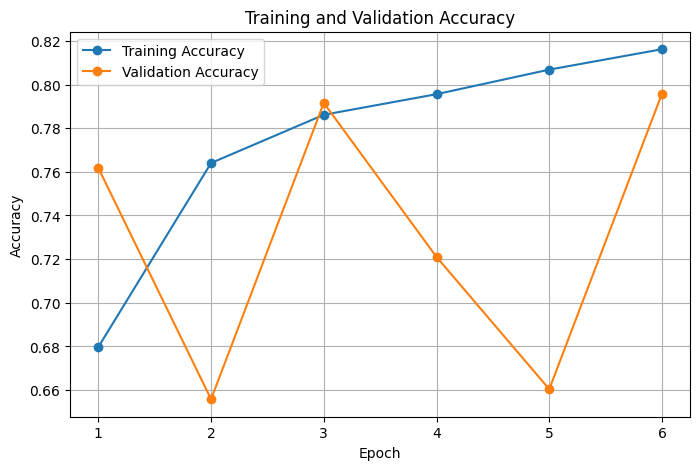

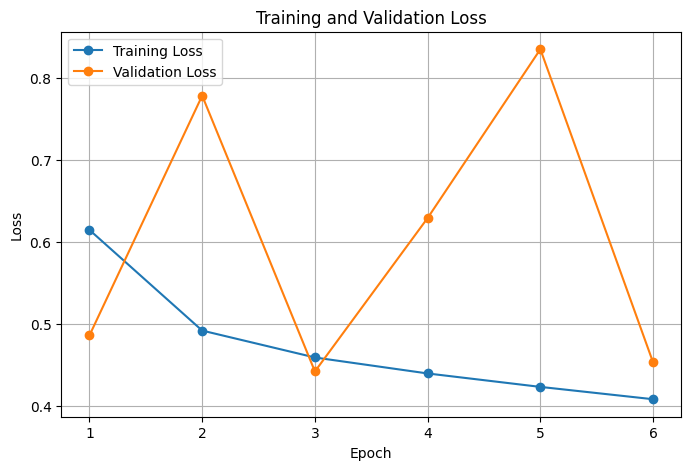

In [14]:
# Plot training and validation performance
epochs = range(1, len(history.history["accuracy"]) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, history.history["accuracy"], marker="o", label="Training Accuracy")
plt.plot(epochs, history.history["val_accuracy"], marker="o", label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epochs, history.history["loss"], marker="o", label="Training Loss")
plt.plot(epochs, history.history["val_loss"], marker="o", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

#### **Training Behavior Observation**

The training curves show a steady improvement on the training set. Training accuracy increased from **67.97%** at epoch 1 to **81.62%** at epoch 6, while training loss decreased from **0.6149** to **0.4084**.

In contrast, the validation performance fluctuated considerably. Validation accuracy changed from 76.18% at epoch 1 to 65.58% at epoch 2, increased to 79.16% at epoch 3, and then decreased again during epochs 4 and 5.

The minimum validation loss occurred at **epoch 3**, where:

- **Validation accuracy:** 79.16%
- **Validation loss:** 0.4422

Although validation accuracy reached 79.58% at epoch 6, its validation loss was higher at 0.4532. Since Early Stopping monitored `val_loss`, the model restored the weights from epoch 3.

The difference between the steadily improving training metrics and the unstable validation metrics suggests that the SGD fine-tuning configuration was relatively sensitive and did not converge smoothly on the validation set.

# **Task 1.5 — Evaluate on the test set**

In [15]:
# Evaluate the restored concatenation model
concat_sgd_test_loss, concat_sgd_test_accuracy = model.evaluate(
    X_test,
    y_test,
    batch_size=64
)

print(f"Test loss: {concat_sgd_test_loss:.4f}")
print(f"Test accuracy: {concat_sgd_test_accuracy:.4f}")

391/391 [==============================] - 37s 94ms/step - loss: 0.4367 - accuracy: 0.7966
Test loss: 0.4367
Test accuracy: 0.7966


In [16]:
# Generate predicted probabilities on the test set
y_prob = model.predict(X_test, batch_size=64)
y_pred = (y_prob >= 0.5).astype("int32").flatten()

print("Prediction shape:", y_pred.shape)
print("First 10 predictions:", y_pred[:10])

391/391 [==============================] - 35s 89ms/step
Prediction shape: (25000,)
First 10 predictions: [0 1 0 0 1 0 1 0 0 0]


### **Test Evaluation**

After Early Stopping restored the weights from epoch 3, the concatenation-based multi-layer BERT model was evaluated on the test set.

The model achieved:

- **Test accuracy:** 79.66%
- **Test loss:** 0.4367

The test accuracy is close to the selected validation accuracy of 79.16%, with a difference of approximately **0.50 percentage points**. This suggests that the restored checkpoint generalized reasonably consistently to the unseen test reviews.

The prediction output also had a shape of `(25000,)`, confirming that one binary sentiment prediction was produced for each test review.

### **Additional Experiment: Baseline vs. Multi-Layer BERT**

In [17]:
# Build the baseline BERT classifier
def build_baseline_bert_model():
    # Raw text input
    text_input = keras.layers.Input(
        shape=(),
        dtype=tf.string,
        name="text"
    )

    # BERT preprocessing
    preprocessing_layer = hub.KerasLayer(
        tfhub_preprocess,
        name="preprocessing"
    )
    encoder_inputs = preprocessing_layer(text_input)

    # Pretrained Small BERT
    encoder = hub.KerasLayer(
        tfhub_model,
        trainable=True,
        name="BERT_encoder"
    )
    outputs = encoder(encoder_inputs)

    # Use the standard pooled BERT representation
    pooled_output = outputs["pooled_output"]

    # Classification head
    net = keras.layers.Dense(
        64,
        activation="relu",
        name="dense"
    )(pooled_output)

    net = keras.layers.BatchNormalization(
        name="batch_normalization"
    )(net)

    net = keras.layers.Dropout(
        0.5,
        name="dropout"
    )(net)

    output = keras.layers.Dense(
        1,
        activation="sigmoid",
        name="classifier"
    )(net)

    return keras.Model(
        inputs=text_input,
        outputs=output,
        name="Baseline_BERT_classifier"
    )


baseline_model = build_baseline_bert_model()
baseline_model.summary()

Model: "Baseline_BERT_classifier"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 text (InputLayer)           [(None,)]                    0         []                            
                                                                                                  
 preprocessing (KerasLayer)  {'input_mask': (None, 128)   0         ['text[0][0]']                
                             , 'input_word_ids': (None,                                           
                              128),                                                               
                              'input_type_ids': (None,                                            
                             128)}                                                                
                                                                           

In [18]:
# Compile the baseline model
baseline_model.compile(
    optimizer=tf.keras.optimizers.SGD(
        learning_rate=0.01
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Use the same stopping rule as the multi-layer model
baseline_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

# Train the baseline model
baseline_history = baseline_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=64,
    callbacks=[baseline_early_stopping]
)

Epoch 1/15
313/313 [==============================] - 64s 178ms/step - loss: 0.6310 - accuracy: 0.6637 - val_loss: 0.5683 - val_accuracy: 0.6978
Epoch 2/15
313/313 [==============================] - 47s 150ms/step - loss: 0.4924 - accuracy: 0.7661 - val_loss: 0.5721 - val_accuracy: 0.7496
Epoch 3/15
313/313 [==============================] - 46s 148ms/step - loss: 0.4582 - accuracy: 0.7855 - val_loss: 0.4682 - val_accuracy: 0.7698
Epoch 4/15
313/313 [==============================] - 46s 146ms/step - loss: 0.4411 - accuracy: 0.7987 - val_loss: 0.4297 - val_accuracy: 0.7962
Epoch 5/15
313/313 [==============================] - 46s 146ms/step - loss: 0.4225 - accuracy: 0.8072 - val_loss: 1.2298 - val_accuracy: 0.5560
Epoch 6/15
313/313 [==============================] - 45s 143ms/step - loss: 0.4103 - accuracy: 0.8141 - val_loss: 0.6240 - val_accuracy: 0.7380
Epoch 7/15
313/313 [==============================] - 45s 143ms/step - loss: 0.4010 - accuracy: 0.8178 - val_loss: 0.5209 - val_ac

In [19]:
# Evaluate the restored baseline model
baseline_test_loss, baseline_test_accuracy = baseline_model.evaluate(
    X_test,
    y_test,
    batch_size=64
)

print(f"Baseline test loss: {baseline_test_loss:.4f}")
print(f"Baseline test accuracy: {baseline_test_accuracy:.4f}")

391/391 [==============================] - 37s 94ms/step - loss: 0.4278 - accuracy: 0.7996
Baseline test loss: 0.4278
Baseline test accuracy: 0.7996


In [41]:
# Get validation metrics from the checkpoint with minimum validation loss
def get_selected_metrics(hist):
    selected_idx = np.argmin(hist.history["val_loss"])

    return (
        selected_idx + 1,
        hist.history["val_accuracy"][selected_idx],
        hist.history["val_loss"][selected_idx]
    )


baseline_epoch, baseline_val_acc, baseline_val_loss = get_selected_metrics(
    baseline_history
)

concat_epoch, concat_val_acc, concat_val_loss = get_selected_metrics(
    history
)

results = pd.DataFrame({
    "Model": [
        "Baseline BERT",
        "Multi-layer BERT"
    ],
    "Selected Epoch": [
        baseline_epoch,
        concat_epoch
    ],
    "Selected Validation Accuracy": [
        baseline_val_acc,
        concat_val_acc
    ],
    "Selected Validation Loss": [
        baseline_val_loss,
        concat_val_loss
    ],
    "Test Accuracy": [
        baseline_test_accuracy,
        concat_sgd_test_accuracy
    ],
    "Test Loss": [
        baseline_test_loss,
        concat_sgd_test_loss
    ]
})

results.round(4)

,Model,Selected Epoch,Selected Validation Accuracy,Selected Validation Loss,Test Accuracy,Test Loss
0,Baseline BERT,4,0.7962,0.4297,0.7996,0.4278
1,Multi-layer BERT,3,0.7916,0.4422,0.7966,0.4367


### **Baseline vs. Multi-Layer BERT Comparison**

To evaluate whether combining features from multiple BERT encoder blocks improves sentiment classification, the concatenation-based multi-layer model was compared with a baseline model using BERT's standard `pooled_output`.

Both models used the same Small BERT encoder, classification head, optimizer, learning rate, batch size, maximum number of epochs, and Early Stopping configuration. The main difference was the representation provided to the classifier:

- **Baseline BERT:** 128-dimensional `pooled_output`
- **Multi-layer BERT:** 512-dimensional representation obtained by concatenating the `[CLS]` features from all four encoder blocks

The pooled-output baseline achieved a selected validation accuracy of **79.62%** and a test accuracy of **79.96%**.

Under the same SGD fine-tuning configuration, the concatenation-based multi-layer model achieved a selected validation accuracy of **79.16%** and a test accuracy of **79.66%**.

Therefore, concatenating the four encoder representations did **not** improve performance over the pooled-output baseline in this training run. The test accuracy was approximately **0.30 percentage points lower** than the baseline.

This result shows that access to features from multiple encoder layers does not automatically lead to better classification performance. The usefulness of multi-layer information also depends on how the features are combined and how the model is fine-tuned.

### **Additional Experiment: Learnable Weighted Combination of Encoder Features**

The previous multi-layer model combined the four encoder representations using concatenation. As an additional experiment, a learnable weighted combination is tested to determine whether the model can learn the relative contribution of each encoder block.

All other training settings are kept unchanged so that the effect of the feature-combination method can be evaluated independently.

In [22]:
# Learnable weighted combination of encoder features
class WeightedLayerFusion(tf.keras.layers.Layer):
    def build(self, input_shape):
        self.layer_weights = self.add_weight(
            name="layer_weights",
            shape=(len(input_shape),),
            initializer="zeros",
            trainable=True
        )

    def call(self, inputs):
        weights = tf.nn.softmax(self.layer_weights)

        # Stack features: (batch, 4, 128)
        stacked_features = tf.stack(inputs, axis=1)

        # Weighted sum across encoder layers
        return tf.reduce_sum(
            stacked_features * weights[None, :, None],
            axis=1
        )

In [23]:
# Build BERT classifier with learnable layer weighting
def build_weighted_bert_model():
    # Raw text input
    text_input = keras.layers.Input(
        shape=(),
        dtype=tf.string,
        name="text"
    )

    # BERT preprocessing
    preprocessing_layer = hub.KerasLayer(
        tfhub_preprocess,
        name="preprocessing"
    )
    encoder_inputs = preprocessing_layer(text_input)

    # Pretrained Small BERT
    encoder = hub.KerasLayer(
        tfhub_model,
        trainable=True,
        name="BERT_encoder"
    )
    outputs = encoder(encoder_inputs)

    # Extract [CLS] feature from each encoder block
    cls_features = [
        layer_output[:, 0, :]
        for layer_output in outputs["encoder_outputs"]
    ]

    # Learn how much each encoder layer contributes
    combined_features = WeightedLayerFusion(
        name="weighted_layer_fusion"
    )(cls_features)

    # Same classification head as previous experiments
    net = keras.layers.Dense(
        64,
        activation="relu",
        name="dense"
    )(combined_features)

    net = keras.layers.BatchNormalization(
        name="batch_normalization"
    )(net)

    net = keras.layers.Dropout(
        0.5,
        name="dropout"
    )(net)

    output = keras.layers.Dense(
        1,
        activation="sigmoid",
        name="classifier"
    )(net)

    return keras.Model(
        inputs=text_input,
        outputs=output,
        name="Weighted_MultiLayer_BERT_classifier"
    )


weighted_model = build_weighted_bert_model()
weighted_model.summary()

Model: "Weighted_MultiLayer_BERT_classifier"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 text (InputLayer)           [(None,)]                    0         []                            
                                                                                                  
 preprocessing (KerasLayer)  {'input_mask': (None, 128)   0         ['text[0][0]']                
                             , 'input_word_ids': (None,                                           
                              128),                                                               
                              'input_type_ids': (None,                                            
                             128)}                                                                
                                                                

In [24]:
# Compile the weighted multi-layer model
weighted_model.compile(
    optimizer=tf.keras.optimizers.SGD(
        learning_rate=0.01
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Use the same Early Stopping configuration
weighted_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

# Train the model
weighted_history = weighted_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=64,
    callbacks=[weighted_early_stopping]
)

Epoch 1/15
313/313 [==============================] - 64s 176ms/step - loss: 0.6514 - accuracy: 0.6467 - val_loss: 0.9484 - val_accuracy: 0.6026
Epoch 2/15
313/313 [==============================] - 49s 157ms/step - loss: 0.5012 - accuracy: 0.7574 - val_loss: 0.4623 - val_accuracy: 0.7750
Epoch 3/15
313/313 [==============================] - 46s 148ms/step - loss: 0.4673 - accuracy: 0.7811 - val_loss: 0.8690 - val_accuracy: 0.6238
Epoch 4/15
313/313 [==============================] - 46s 148ms/step - loss: 0.4462 - accuracy: 0.7951 - val_loss: 0.7660 - val_accuracy: 0.6468
Epoch 5/15
313/313 [==============================] - 45s 145ms/step - loss: 0.4297 - accuracy: 0.8030 - val_loss: 0.4293 - val_accuracy: 0.7994
Epoch 6/15
313/313 [==============================] - 45s 143ms/step - loss: 0.4146 - accuracy: 0.8123 - val_loss: 0.5251 - val_accuracy: 0.7636
Epoch 7/15
313/313 [==============================] - 45s 144ms/step - loss: 0.4052 - accuracy: 0.8184 - val_loss: 0.6777 - val_ac

In [25]:
# Inspect the learned contribution of each encoder block
fusion_layer = weighted_model.get_layer("weighted_layer_fusion")

learned_weights = tf.nn.softmax(
    fusion_layer.layer_weights
).numpy()

for i, weight in enumerate(learned_weights):
    print(f"Encoder block {i + 1}: {weight:.4f}")

print("\nSum of weights:", learned_weights.sum())

Encoder block 1: 0.2412
Encoder block 2: 0.2423
Encoder block 3: 0.2507
Encoder block 4: 0.2659

Sum of weights: 1.0


In [26]:
# Evaluate the weighted model on the test set
weighted_test_loss, weighted_test_accuracy = weighted_model.evaluate(
    X_test,
    y_test,
    batch_size=64
)

print(f"Weighted model test loss: {weighted_test_loss:.4f}")
print(f"Weighted model test accuracy: {weighted_test_accuracy:.4f}")

391/391 [==============================] - 36s 93ms/step - loss: 0.4258 - accuracy: 0.8019
Weighted model test loss: 0.4258
Weighted model test accuracy: 0.8019


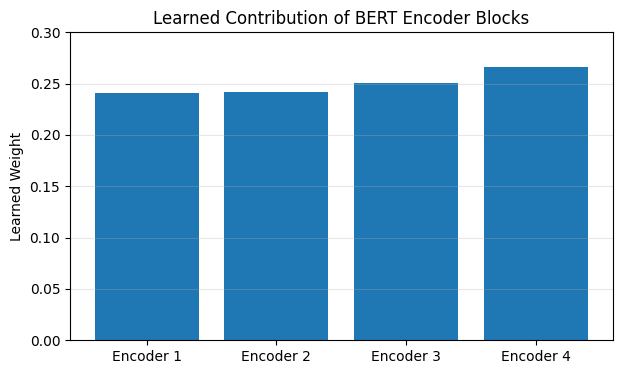

In [27]:
# Plot learned weights of the four encoder blocks
encoder_names = [
    "Encoder 1",
    "Encoder 2",
    "Encoder 3",
    "Encoder 4"
]

plt.figure(figsize=(7, 4))

plt.bar(
    encoder_names,
    learned_weights
)

plt.ylabel("Learned Weight")
plt.title("Learned Contribution of BERT Encoder Blocks")
plt.ylim(0, 0.30)
plt.grid(axis="y", alpha=0.3)

plt.show()

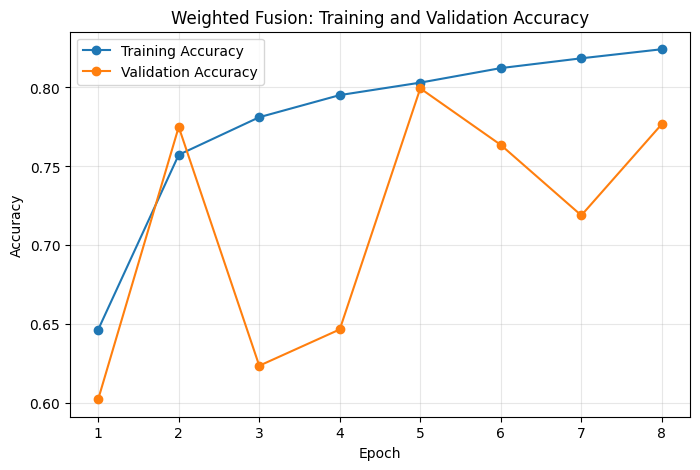

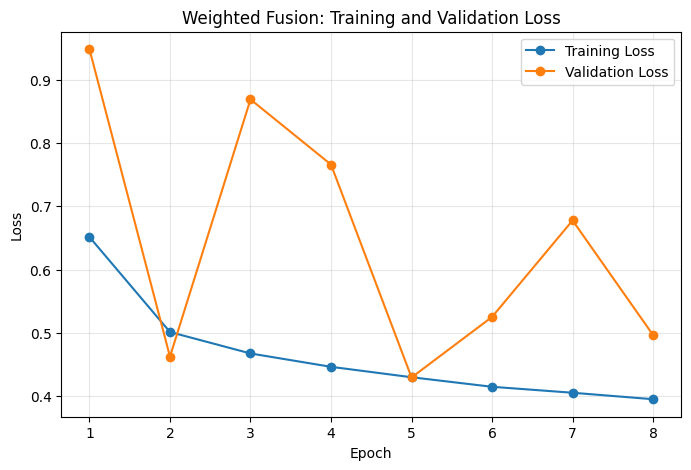

In [28]:
# Plot training and validation performance
epochs = range(1, len(weighted_history.history["accuracy"]) + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    weighted_history.history["accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs,
    weighted_history.history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Weighted Fusion: Training and Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)

plt.show()


plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    weighted_history.history["loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    weighted_history.history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Weighted Fusion: Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

#### **Learnable Weighted Fusion Results**

As an alternative to concatenation, a learnable weighted combination was used to combine the `[CLS]` representations from the four BERT encoder blocks.

After training, the learned weights were:

- **Encoder block 1:** 0.2412
- **Encoder block 2:** 0.2423
- **Encoder block 3:** 0.2507
- **Encoder block 4:** 0.2659

The weights remained relatively balanced, although the model assigned a slightly larger contribution to the deeper encoder blocks. This indicates that the final representation used information from all four levels rather than relying primarily on a single layer.

Early Stopping restored the weights from **epoch 5**, where the model achieved a validation accuracy of **79.94%** and a validation loss of **0.4293**.

On the test set, the weighted-fusion model achieved:

- **Test accuracy:** 80.19%
- **Test loss:** 0.4258

Weighted fusion therefore performed better than the concatenation-based SGD model, which achieved 79.66% test accuracy, and slightly outperformed the pooled-output baseline at 79.96%.

The improvement over the baseline was small, approximately **0.23 percentage points**, so it should not be interpreted as evidence that weighted fusion is universally superior. However, in this experiment, the learnable combination provided the strongest performance among the SGD-based configurations while retaining a compact 128-dimensional representation.

### **Additional Experiment: Fine-Tuning Optimization Strategy**

The original concatenation-based multi-layer model was fine-tuned using SGD with a learning rate of `0.01`. The validation results showed noticeable fluctuations during training.

As an additional experiment, the same model architecture was fine-tuned using Adam with a learning rate of `2e-5`.

The model architecture, batch size, maximum number of epochs, and Early Stopping configuration were kept unchanged. Therefore, this experiment evaluates an alternative optimization strategy while keeping the multi-layer feature representation fixed.

In [30]:
# Build a fresh concatenation-based model
adam_model = build_multilayer_bert_model()

adam_model.summary()

Model: "MultiLayer_BERT_classifier"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 text (InputLayer)           [(None,)]                    0         []                            
                                                                                                  
 preprocessing (KerasLayer)  {'input_mask': (None, 128)   0         ['text[0][0]']                
                             , 'input_word_ids': (None,                                           
                              128),                                                               
                              'input_type_ids': (None,                                            
                             128)}                                                                
                                                                         

In [31]:
# Compile with Adam and a smaller fine-tuning learning rate
adam_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=2e-5
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

adam_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

In [32]:
# Train using the same training configuration
adam_history = adam_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=64,
    callbacks=[adam_early_stopping]
)

Epoch 1/15
313/313 [==============================] - 83s 223ms/step - loss: 0.7813 - accuracy: 0.5803 - val_loss: 0.5792 - val_accuracy: 0.6924
Epoch 2/15
313/313 [==============================] - 56s 180ms/step - loss: 0.6374 - accuracy: 0.6798 - val_loss: 0.5333 - val_accuracy: 0.7420
Epoch 3/15
313/313 [==============================] - 51s 162ms/step - loss: 0.5423 - accuracy: 0.7419 - val_loss: 0.4810 - val_accuracy: 0.7706
Epoch 4/15
313/313 [==============================] - 54s 173ms/step - loss: 0.5036 - accuracy: 0.7702 - val_loss: 0.4885 - val_accuracy: 0.7764
Epoch 5/15
313/313 [==============================] - 50s 159ms/step - loss: 0.4678 - accuracy: 0.7872 - val_loss: 0.4508 - val_accuracy: 0.7960
Epoch 6/15
313/313 [==============================] - 50s 161ms/step - loss: 0.4364 - accuracy: 0.8054 - val_loss: 0.4394 - val_accuracy: 0.7990
Epoch 7/15
313/313 [==============================] - 49s 156ms/step - loss: 0.4160 - accuracy: 0.8163 - val_loss: 0.4283 - val_ac

In [33]:
# Summarize validation performance
best_adam_val_acc = max(adam_history.history["val_accuracy"])
best_adam_val_loss = min(adam_history.history["val_loss"])

best_adam_acc_epoch = (
    np.argmax(adam_history.history["val_accuracy"]) + 1
)

best_adam_loss_epoch = (
    np.argmin(adam_history.history["val_loss"]) + 1
)

print(
    f"Best validation accuracy: "
    f"{best_adam_val_acc:.4f} "
    f"(epoch {best_adam_acc_epoch})"
)

print(
    f"Best validation loss: "
    f"{best_adam_val_loss:.4f} "
    f"(epoch {best_adam_loss_epoch})"
)

Best validation accuracy: 0.8114 (epoch 8)
Best validation loss: 0.4266 (epoch 8)


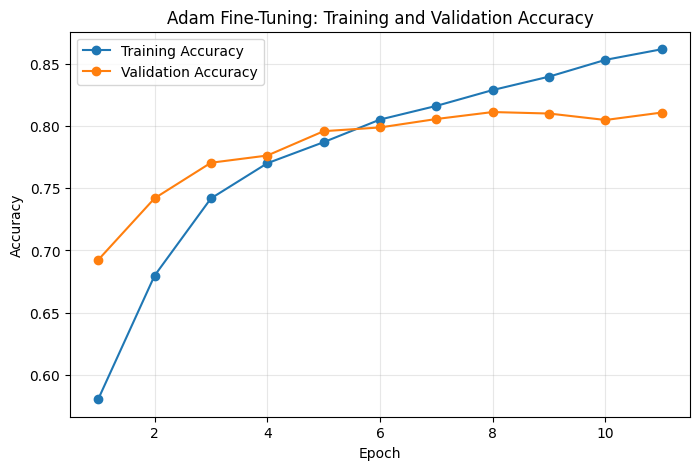

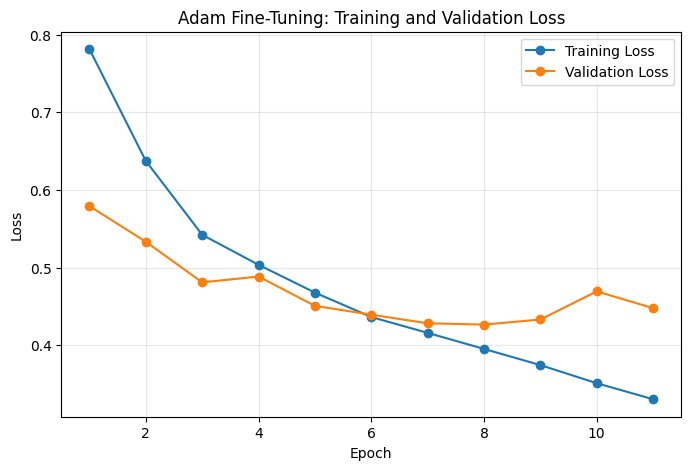

In [34]:
# Plot Adam fine-tuning performance
epochs = range(1, len(adam_history.history["accuracy"]) + 1)

plt.figure(figsize=(8, 5))
plt.plot(
    epochs,
    adam_history.history["accuracy"],
    marker="o",
    label="Training Accuracy"
)
plt.plot(
    epochs,
    adam_history.history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Adam Fine-Tuning: Training and Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


plt.figure(figsize=(8, 5))
plt.plot(
    epochs,
    adam_history.history["loss"],
    marker="o",
    label="Training Loss"
)
plt.plot(
    epochs,
    adam_history.history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Adam Fine-Tuning: Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### **Fine-Tuning Strategy: Results and Interpretation**

Using Adam with a learning rate of `2e-5` substantially improved the validation performance of the concatenation-based multi-layer BERT model compared with the original SGD configuration.

The selected checkpoints achieved:

- **Concatenation + SGD:** 79.16% validation accuracy, 0.4422 validation loss
- **Concatenation + Adam:** 81.14% validation accuracy, 0.4266 validation loss

This corresponds to an improvement of approximately **1.98 percentage points in validation accuracy**.

The Adam training curves also show a more gradual convergence pattern. Validation performance improved consistently during the earlier epochs, reaching its minimum validation loss at **epoch 8**. After this point, training accuracy continued to increase while validation loss began to rise, indicating the beginning of overfitting.

Early Stopping stopped training after epoch 11 and restored the weights from epoch 8. At the selected checkpoint, the model achieved:

- **Training accuracy:** 82.91%
- **Validation accuracy:** 81.14%
- **Validation loss:** 0.4266

Because both the optimizer and learning rate were changed together, this experiment cannot determine whether the improvement was caused specifically by Adam, the smaller learning rate, or their combination. However, the results clearly show that the alternative fine-tuning configuration produced more stable convergence and substantially better validation performance than the original SGD setup.

In [36]:
# Evaluate the final selected model on the test set
final_test_loss, final_test_accuracy = adam_model.evaluate(
    X_test,
    y_test,
    batch_size=64
)

print(f"Final test loss: {final_test_loss:.4f}")
print(f"Final test accuracy: {final_test_accuracy:.4f}")

391/391 [==============================] - 40s 102ms/step - loss: 0.4282 - accuracy: 0.8124
Final test loss: 0.4282
Final test accuracy: 0.8124


In [37]:
# Generate predictions from the final model
final_prob = adam_model.predict(
    X_test,
    batch_size=64
)

final_pred = (final_prob >= 0.5).astype("int32").flatten()

print("Prediction shape:", final_pred.shape)
print("First 10 predictions:", final_pred[:10])

391/391 [==============================] - 38s 97ms/step
Prediction shape: (25000,)
First 10 predictions: [0 0 0 0 1 0 1 0 0 0]


#### **Final Model Evaluation**

Based on the validation experiments, the concatenation-based multi-layer BERT model fine-tuned with Adam at a learning rate of `2e-5` was selected as the final configuration.

Early Stopping restored the checkpoint from **epoch 8**, where the model achieved a validation accuracy of **81.14%** and a validation loss of **0.4266**.

The selected model was then evaluated on the test set and achieved:

- **Test accuracy:** 81.24%
- **Test loss:** 0.4282

The validation and test accuracies differ by only **0.10 percentage points**, while the validation and test losses are also very similar. This indicates consistent generalization from the validation set to the unseen test reviews.

Compared with the pooled-output BERT baseline, which achieved **79.96% test accuracy**, the final model achieved approximately **1.28 percentage points higher test accuracy**.

Among the configurations evaluated, concatenating the four encoder representations and fine-tuning with Adam at `2e-5` produced the highest classification accuracy.

In [46]:
# Get metrics from the checkpoint selected by validation loss
def selected_validation_metrics(hist):
    selected_idx = np.argmin(hist.history["val_loss"])

    return (
        selected_idx + 1,
        hist.history["val_accuracy"][selected_idx],
        hist.history["val_loss"][selected_idx]
    )


baseline_epoch, baseline_val_acc, baseline_val_loss = (
    selected_validation_metrics(baseline_history)
)

concat_epoch, concat_val_acc, concat_val_loss = (
    selected_validation_metrics(history)
)

weighted_epoch, weighted_val_acc, weighted_val_loss = (
    selected_validation_metrics(weighted_history)
)

adam_epoch, adam_val_acc, adam_val_loss = (
    selected_validation_metrics(adam_history)
)


final_results = pd.DataFrame({
    "Model": [
        "Baseline pooled BERT",
        "Concatenation + SGD",
        "Weighted fusion + SGD",
        "Concatenation + Adam"
    ],
    "Selected Epoch": [
        baseline_epoch,
        concat_epoch,
        weighted_epoch,
        adam_epoch
    ],
    "Selected Validation Accuracy": [
        baseline_val_acc,
        concat_val_acc,
        weighted_val_acc,
        adam_val_acc
    ],
    "Selected Validation Loss": [
        baseline_val_loss,
        concat_val_loss,
        weighted_val_loss,
        adam_val_loss
    ],
    "Test Accuracy": [
        baseline_test_accuracy,
        concat_sgd_test_accuracy,
        weighted_test_accuracy,
        final_test_accuracy
    ],
    "Test Loss": [
        baseline_test_loss,
        concat_sgd_test_loss,
        weighted_test_loss,
        final_test_loss
    ]
})

final_results.round(4)

,Model,Selected Epoch,Selected Validation Accuracy,Selected Validation Loss,Test Accuracy,Test Loss
0,Baseline pooled BERT,4,0.7962,0.4297,0.7996,0.4278
1,Concatenation + SGD,3,0.7916,0.4422,0.7966,0.4367
2,Weighted fusion + SGD,5,0.7994,0.4293,0.8019,0.4258
3,Concatenation + Adam,8,0.8114,0.4266,0.8124,0.4282


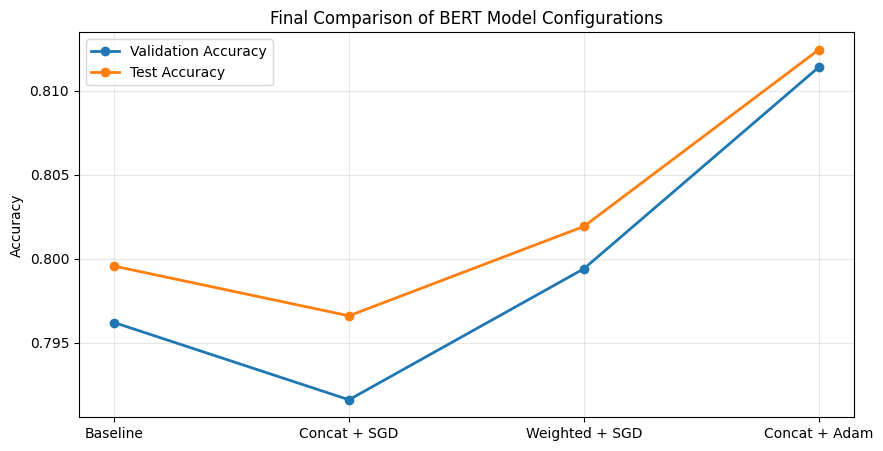

In [44]:
x = np.arange(len(final_results))

plt.figure(figsize=(10, 5))

plt.plot(
    x,
    final_results["Selected Validation Accuracy"],
    marker="o",
    linewidth=2,
    label="Validation Accuracy"
)

plt.plot(
    x,
    final_results["Test Accuracy"],
    marker="o",
    linewidth=2,
    label="Test Accuracy"
)

plt.xticks(
    x,
    ["Baseline", "Concat + SGD", "Weighted + SGD", "Concat + Adam"]
)

plt.ylabel("Accuracy")
plt.title("Final Comparison of BERT Model Configurations")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

#### **Final Comparison of Model Configurations**

The final experiments show that the effect of multi-layer BERT features depends strongly on both the feature-combination method and the fine-tuning strategy.

The pooled-output baseline achieved **79.96% test accuracy**. Simply concatenating the four encoder representations while using SGD did not improve performance, producing **79.66% test accuracy**.

The learnable weighted-fusion strategy performed slightly better, reaching **80.19% test accuracy** and the lowest test loss of **0.4258** among the evaluated models. This suggests that multi-layer information can be useful, but the method used to combine the encoder representations is important.

The largest improvement came from the fine-tuning strategy. Using the concatenation representation together with Adam at a learning rate of `2e-5` achieved the highest test accuracy of **81.24%**, approximately **1.28 percentage points above the pooled-output baseline**.

Overall, the experiments do not show that multi-layer features automatically outperform the standard BERT representation. Instead, they indicate that multi-layer representations can be beneficial when they are combined and optimized appropriately. Among the evaluated configurations, **concatenation with Adam fine-tuning at `2e-5` achieved the highest classification accuracy**.

## 2. Open discussion questions

### **2.1 Effect of Preprocessing on Embedding Quality**

Preprocessing is a critical step because BERT does not operate directly on raw text. The quality of the embeddings depends on whether the input text is converted into the same representation that the pretrained BERT model expects.

First, **tokenization** determines how the review is divided into tokens and mapped to vocabulary IDs. Using the BERT preprocessing module ensures that the tokenization scheme is consistent with the pretrained model and that special tokens such as `[CLS]` and `[SEP]` are inserted correctly. This is particularly important in this assignment because the `[CLS]` representation from each encoder block is used as the review-level feature for classification.

Second, **padding and attention masking** allow reviews of different lengths to be represented using a fixed input size. Padding tokens themselves should not contribute useful semantic information, so `input_mask` identifies which positions contain real tokens and which positions are only padding. This allows the Transformer to focus on the actual review content rather than padded positions.

Another important factor is **sequence length and truncation**. In the current setup, each review is represented using a maximum sequence length of 128 tokens. This improves computational efficiency, but longer reviews may contain information beyond the first 128 tokens. If important sentiment cues occur in the truncated portion of a review, that information cannot be represented by BERT or recovered later during fine-tuning. Therefore, sequence length creates a trade-off between computational cost and the amount of contextual information available to the model.

Preprocessing is therefore especially important during fine-tuning. Fine-tuning can adapt the pretrained BERT parameters to the sentiment classification task, but it cannot compensate for incorrectly tokenized input or recover information that has already been removed during preprocessing. In this assignment, using the preprocessing module associated with the pretrained Small BERT model helps ensure that the input representation remains compatible with the representations learned during pretraining.

Overall, preprocessing can be viewed as the interface between the raw movie reviews and the pretrained BERT model. Correct tokenization, masking, and sequence-length selection directly affect the contextual information available to the encoder and therefore influence the quality of the resulting embeddings and the final sentiment classification performance.

### **2.2 Impact of Multi-Layer BERT Features**

Each BERT encoder block produces a contextual representation of the input, so representations from different depths may contain complementary information. Lower layers tend to retain more local and lexical information, while representations become progressively more contextualized as they pass through additional Transformer blocks.

For sentiment classification, both types of information can potentially be useful. Individual sentiment-bearing words provide local signals, while more contextual representations are needed to interpret interactions such as negation and contrast.

However, the experimental results show that simply using more layers does not automatically improve performance. The pooled-output baseline achieved **79.96% test accuracy**, while concatenating the `[CLS]` features from all four encoder blocks with the same SGD fine-tuning configuration achieved **79.66%**.

When the encoder representations were combined using learnable weighted fusion, test accuracy increased to **80.19%**. The learned weights remained relatively balanced:

- Encoder 1: 0.2412
- Encoder 2: 0.2423
- Encoder 3: 0.2507
- Encoder 4: 0.2659

This suggests that information from multiple encoder depths contributed to the representation, with a slight preference toward the deeper layers.

The results therefore suggest that multi-layer BERT representations can provide useful complementary information, but their effectiveness depends on how those features are combined and how the overall model is fine-tuned. Multi-layer extraction alone is not sufficient to guarantee improved classification performance.

### **2.3 Training Challenges, Overfitting, and Convergence**

One of the main challenges during BERT fine-tuning was unstable validation performance, particularly when SGD with a learning rate of `0.01` was used.

For the concatenation model, training loss decreased consistently from 0.6149 to 0.4084, while validation loss fluctuated substantially between **0.4422 and 0.8353** after the first epoch. Validation accuracy also varied considerably even as training accuracy continued to increase. Early Stopping therefore restored the model from epoch 3 instead of using the final epoch.

Similar instability occurred in the pooled-output baseline and weighted-fusion experiments. For example, the baseline validation accuracy fell to **55.60% at epoch 5** despite continued improvement in training accuracy.

The Adam-based fine-tuning strategy showed a more gradual convergence pattern. Validation loss decreased from 0.5792 to its minimum of **0.4266 at epoch 8**, while validation accuracy increased to **81.14%**. After epoch 8, training accuracy continued increasing, but validation loss began to rise. By epoch 11, training accuracy had reached 86.19% while validation accuracy remained around 81.10%, showing a growing train-validation gap and indicating the beginning of overfitting.

Early Stopping was therefore important for all experiments because the final training epoch was not necessarily the checkpoint with the best validation performance.

Training time was also a practical challenge because the BERT encoder remained trainable. Most epochs required approximately **45–83 seconds** in the current environment, making repeated fine-tuning experiments considerably more expensive than training only a small classification head.

Overall, the main challenges were validation instability, increasing overfitting during later epochs, and computational cost. Early Stopping and the Adam-based fine-tuning configuration helped produce more stable convergence and better validation performance.

In [45]:
def summarize_training(name, hist):
    selected_idx = np.argmin(hist.history["val_loss"])

    train_acc = hist.history["accuracy"][selected_idx]
    val_acc = hist.history["val_accuracy"][selected_idx]
    val_loss = hist.history["val_loss"][selected_idx]

    return {
        "Model": name,
        "Selected Epoch": selected_idx + 1,
        "Training Accuracy": train_acc,
        "Validation Accuracy": val_acc,
        "Train-Val Gap": train_acc - val_acc,
        "Validation Loss": val_loss
    }


training_summary = pd.DataFrame([
    summarize_training("Baseline", baseline_history),
    summarize_training("Concatenation + SGD", history),
    summarize_training("Weighted Fusion + SGD", weighted_history),
    summarize_training("Concatenation + Adam", adam_history)
])

training_summary.round(4)

,Model,Selected Epoch,Training Accuracy,Validation Accuracy,Train-Val Gap,Validation Loss
0,Baseline,4,0.7987,0.7962,0.0025,0.4297
1,Concatenation + SGD,3,0.7861,0.7916,-0.0055,0.4422
2,Weighted Fusion + SGD,5,0.8030,0.7994,0.0037,0.4293
3,Concatenation + Adam,8,0.8291,0.8114,0.0177,0.4266


### **2.4 Suitability of BERT for Sentiment Analysis**

BERT is well-suited for sentiment analysis because sentiment often depends on the context in which words appear rather than on individual words alone.

A major advantage of BERT is its **bidirectional contextual representation**. Each token is represented using information from both its left and right context. This is useful for sentiment classification because the meaning of a sentiment-bearing word can change depending on surrounding words. For example, phrases such as *“not good”*, *“better than expected”*, or *“the acting was good, but the story was disappointing”* cannot be interpreted reliably by considering individual words independently.

BERT also benefits from **pretraining on large amounts of unlabeled text**. Instead of learning language representations entirely from the IMDB training set, the model begins with pretrained contextual representations and then adapts them to the sentiment classification task through fine-tuning. This makes BERT particularly useful when the downstream dataset is much smaller than the corpus required to learn general language representations from scratch.

The results from this assignment support the suitability of BERT for sentiment classification. The standard pooled-output BERT baseline achieved **79.96% test accuracy**, while the best configuration, using multi-layer concatenation and Adam fine-tuning, achieved **81.24%**. These results show that pretrained BERT representations contain useful information for distinguishing positive and negative movie reviews and can be further adapted to the downstream sentiment classification task.

However, BERT also has limitations. Fine-tuning is computationally more expensive than training simpler text classifiers, and performance can be sensitive to optimization settings such as the learning rate. In this assignment, changing the fine-tuning strategy produced a noticeable difference in validation performance, showing that pretrained BERT still requires careful optimization.

Other approaches could also be effective for sentiment classification. Traditional methods such as **TF-IDF features with Logistic Regression or Support Vector Machines** can provide strong and computationally inexpensive baselines. Neural approaches such as **CNNs for text classification** or **LSTM/GRU networks** can learn sequential or local patterns directly from token representations. More recent pretrained Transformer models can also be used, especially when computational resources or task requirements differ.

Overall, BERT provides a strong balance between pretrained language knowledge and task-specific adaptation. Its ability to model contextual relationships makes it particularly appropriate for sentiment analysis, although simpler models may still be preferable when computational efficiency, interpretability, or deployment cost is more important than maximizing predictive performance.

### **2.5 Possible Improvements**

Several improvements were explored during this assignment, particularly in the areas of multi-layer feature combination and BERT fine-tuning.

First, the pretrained BERT encoder was kept **trainable**, allowing its parameters to adapt to the IMDB sentiment classification task rather than using BERT only as a fixed feature extractor.

Different methods for combining the four encoder representations were also investigated. Simple concatenation with SGD achieved **79.66% test accuracy**, slightly below the pooled-output baseline at **79.96%**. In contrast, learnable weighted fusion achieved **80.19%**, indicating that the method used to combine multi-layer representations can influence performance.

The fine-tuning strategy produced a larger improvement. Using the same concatenation-based representation but replacing SGD at `0.01` with Adam at `2e-5` increased the selected validation accuracy from **79.16% to 81.14%** and produced a final test accuracy of **81.24%**.

These results suggest that optimization strategy had a larger effect on performance than the difference between the tested feature-combination methods.

If the model were improved further, I would consider increasing the maximum sequence length beyond 128 tokens so that less information is truncated from long reviews, although this would increase computational cost. I would also investigate alternative pooling strategies, such as mean pooling over valid token representations instead of relying only on the `[CLS]` position.

Finally, evaluating each configuration across multiple random seeds would help determine whether the relatively small differences between some models, particularly the baseline and weighted-fusion configurations, are consistent or simply caused by training variability.

Overall, the experiments show that multi-layer BERT features can be useful, but they do not automatically improve performance. Among the configurations tested, the most important improvement came from the fine-tuning strategy, with concatenation and Adam at `2e-5` achieving the highest classification accuracy.